# Ex08


Tự viết toàn bộ code. File này không có lời giải.

Làm lần lượt sáu phần:

1. Mã hóa (LabelEncoder và OneHotEncoder)
2. Ghép thành một bảng số duy nhất (concat)
3. Chuẩn hóa (StandardScaler hoặc MinMaxScaler)
4. Đưa bảng đã chuẩn hóa vào KMeans để gom cụm
5. Elbow để xem k
6. KNN để dự đoán Response

Dữ liệu: data/marketing_campaign.csv, dấu phân tách là tab.

Dùng đúng các cột sau, không thêm cột khác vào bảng đưa vào mô hình:

| Cột | Việc phải làm |
|---|---|
| Education | LabelEncoder |
| Marital_Status | OneHotEncoder |
| Income, Recency, MntWines, MntMeatProducts | giữ nguyên, vì đã là số |

Bỏ các dòng thiếu Income trước khi mã hóa. Không đưa Response vào bảng đặc trưng. Response chỉ dùng làm nhãn ở phần KNN.

random_state=0. Với KMeans đặt thêm n_init=10.


## 1. Mã hóa

Education và Marital_Status là chữ. KMeans không nhận chữ.

In classes_ của LabelEncoder sau khi fit. In tên cột do OneHotEncoder sinh ra.


In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [ ]:
# (Mã hóa dữ liệu):


# Đọc dữ liệu, file sử dụng dấu tab để phân cách
df = pd.read_csv('marketing_campaign.csv', sep='\t')

# Bỏ các dòng bị thiếu Income
df.dropna(subset=['Income'], inplace=True)

# Mã hóa Education bằng LabelEncoder
le = LabelEncoder()
education = le.fit_transform(df['Education'])

# In thứ tự các nhãn mà LabelEncoder đã sắp xếp
print('Education classes:')
print(le.classes_)

# Mã hóa Marital_Status bằng OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
marital_status = ohe.fit_transform(df[['Marital_Status']])

# Lấy tên các cột sau khi mã hóa
marital_columns = ohe.get_feature_names_out(['Marital_Status'])

print('\nCác cột sau khi OneHotEncoder:')
print(marital_columns)


Education classes:
['2n Cycle' 'Basic' 'Graduation' 'Master' 'PhD']

Các cột sau khi OneHotEncoder:
['Marital_Status_Absurd' 'Marital_Status_Alone' 'Marital_Status_Divorced'
 'Marital_Status_Married' 'Marital_Status_Single'
 'Marital_Status_Together' 'Marital_Status_Widow' 'Marital_Status_YOLO']


**Trả lời, không cần code.**

1. LabelEncoder xếp Education theo thứ tự nào? Thứ tự đó có phải Basic, rồi 2n Cycle, Graduation, Master, PhD hay không?
2. Vì sao Marital_Status dùng OneHotEncoder còn Education lại dùng LabelEncoder trong bài này?


In [16]:
# Câu 1. LabelEncoder sắp xếp Education theo thứ tự chữ cái, cụ thể là 2n Cycle, Basic, Graduation, Master, PhD. 
# Thứ tự này không phải thứ tự trình độ học vấn từ thấp đến cao mà đề nêu.

# Câu 2. Marital_Status dùng OneHotEncoder vì các trạng thái hôn nhân không có thứ tự hơn kém tự nhiên. 
# Nếu dùng LabelEncoder, các trạng thái sẽ bị gán số khác nhau, dễ tạo cảm giác có thứ tự. 
# Education dùng LabelEncoder theo đúng yêu cầu bài tập, dù cách mã hóa này cũng không thể hiện hoàn toàn chính xác khoảng cách giữa các trình độ học vấn.

## 2. Ghép thành một bảng số duy nhất

Ghép ba khối theo cột: số của Education, các cột biến giả của Marital_Status, và bốn cột số. Kết quả là một DataFrame, mọi cột đều là số, số dòng bằng số dòng sau khi bỏ Income thiếu.

In shape và columns.


In [17]:
# (Ghép thành một bảng dữ liệu số):
# Chuyển Education thành DataFrame để ghép bảng
df_education = pd.DataFrame(
    {'Education': education},
    index=df.index
)

# Chuyển các cột Marital_Status thành DataFrame
df_marital = pd.DataFrame(
    marital_status,
    columns=marital_columns,
    index=df.index
)

# Lấy đúng bốn cột số theo yêu cầu đề bài
df_numeric = df[
    ['Income', 'Recency', 'MntWines', 'MntMeatProducts']
]

# Ghép ba phần theo cột
df_model = pd.concat(
    [df_education, df_marital, df_numeric],
    axis=1
)

# In kích thước và tên các cột
print('Shape:', df_model.shape)
print('\nColumns:')
print(df_model.columns.tolist())

# Xem thử dữ liệu
df_model.head()



Shape: (2216, 13)

Columns:
['Education', 'Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO', 'Income', 'Recency', 'MntWines', 'MntMeatProducts']


,Education,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO,Income,Recency,MntWines,MntMeatProducts
0,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,58138.0,58,635,546
1,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,46344.0,38,11,6
2,2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,71613.0,26,426,127
3,2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,26646.0,26,11,20
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,58293.0,94,173,118


**Trả lời.**

3. Bảng ghép có bao nhiêu dòng, bao nhiêu cột? Kể tên các cột biến giả.


In [18]:
# Bảng ghép có 2.216 dòng và 13 cột. 
# Các cột biến giả là Marital_Status_Absurd, Marital_Status_Alone, Marital_Status_Divorced, Marital_Status_Married, 
# Marital_Status_Single, Marital_Status_Together, Marital_Status_Widow và Marital_Status_YOLO.

## 3. Chuẩn hóa

Chọn một trong hai: StandardScaler hoặc MinMaxScaler. Fit trên toàn bộ bảng vừa ghép. In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số.


In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
# (Chuẩn hóa dữ liệu):

# Tạo scaler để chuẩn hóa dữ liệu
scaler = StandardScaler()

# Chuẩn hóa toàn bộ bảng dữ liệu đã ghép
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_model),
    columns=df_model.columns,
    index=df_model.index
)

# In trung bình từng cột sau khi chuẩn hóa
print(df_scaled.mean().round(3))



Education                  0.0
Marital_Status_Absurd     -0.0
Marital_Status_Alone       0.0
Marital_Status_Divorced   -0.0
Marital_Status_Married    -0.0
Marital_Status_Single     -0.0
Marital_Status_Together   -0.0
Marital_Status_Widow       0.0
Marital_Status_YOLO        0.0
Income                     0.0
Recency                   -0.0
MntWines                  -0.0
MntMeatProducts           -0.0
dtype: float64


**Trả lời.**

4. Bạn chọn scaler nào? Income và MntWines sẽ chi phối khoảng cách thế nào nếu bỏ bước này?


In [21]:
# Tui chọn StandardScaler. Nếu không chuẩn hóa, Income có giá trị hàng chục nghìn, còn Recency thường chỉ từ 0 đến 99. 
# Vì K-Means sử dụng khoảng cách để gom cụm nên các cột có độ lớn và độ phân tán lớn có thể chi phối kết quả. 
# Chuẩn hóa giúp các đặc trưng có thang đo phù hợp hơn khi tính khoảng cách.

## 4. K-Means

n_clusters=3. In số dòng mỗi cụm và trung bình Income, Recency, MntWines, MntMeatProducts theo cụm. Trung bình tính trên giá trị gốc, không tính trên bảng đã scale.


In [22]:
from sklearn.cluster import KMeans

In [23]:
# (K-Means với 3 cụm):

# Khởi tạo mô hình K-Means với 3 cụm
kmeans = KMeans(
    n_clusters=3,
    random_state=0,
    n_init=10
)

# Huấn luyện mô hình trên dữ liệu đã chuẩn hóa
kmeans.fit(df_scaled)

# Gán nhãn cụm cho từng dòng
df_cluster = df_model.copy()
df_cluster['Cluster'] = kmeans.labels_

# In số dòng thuộc từng cụm
print('Số dòng mỗi cụm:')
print(df_cluster['Cluster'].value_counts().sort_index())

# Tính trung bình trên dữ liệu gốc
print('\nTrung bình các cột theo cụm:')
print(
    df_cluster.groupby('Cluster')[
        ['Income', 'Recency', 'MntWines', 'MntMeatProducts']
    ].mean().round(2)
)


Số dòng mỗi cụm:
Cluster
0    549
1    857
2    810
Name: count, dtype: int64

Trung bình các cột theo cụm:
           Income  Recency  MntWines  MntMeatProducts
Cluster                                              
0        51832.68    49.16    302.06           185.38
1        51724.98    48.31    299.86           160.90
2        53080.82    49.66    312.69           160.99


**Trả lời.**

5. Ba cụm khác nhau ở mức chi tiêu nào? Gọi tên mỗi cụm bằng chữ, không bằng id 0, 1, 2.
6. Đổi random_state thì id cụm có thể đảo. Cách đọc ở câu 5 còn đúng không?


In [24]:
# Câu 5. Ba cụm có mức thu nhập và mức độ gần đây của lần mua sắm khá tương đồng. Khác biệt rõ hơn nằm ở chi tiêu:
# - Cụm 0: chi tiêu cho thịt cao nhất trong ba cụm, trung bình 185,38.
# - Cụm 1: chi tiêu cho rượu vang thấp nhất, trung bình 299,86.
# - Cụm 2: thu nhập và chi tiêu cho rượu vang cao nhất, nhưng chi tiêu cho thịt thấp hơn cụm 0.
# Có thể gọi tên tương đối là nhóm chi tiêu thịt cao, nhóm chi tiêu rượu vang thấp và nhóm thu nhập, chi tiêu rượu vang cao. 
# Ba nhóm này vẫn khá giống nhau ở một số đặc trưng nên không nên kết luận rằng chúng khác biệt hoàn toàn.

# Câu 6. Nếu thay đổi random_state, nhãn cụm 0, 1, 2 có thể đổi vị trí. 
# Vì vậy, không nên dựa riêng vào ID cụm để kết luận. Cần xem lại các giá trị trung bình và đặc điểm của từng cụm trước khi đặt tên.

## 5. Elbow

Dùng đúng bảng đã chuẩn hóa ở phần 3. Thử k từ 1 đến 8. Với mỗi k, lưu inertia. Vẽ inertia theo k, trục hoành là k, trục tung là inertia.


In [25]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k = 1, inertia = 28808.00
k = 2, inertia = 25276.26
k = 3, inertia = 22722.67
k = 4, inertia = 20107.03
k = 5, inertia = 17726.25
k = 6, inertia = 15648.54
k = 7, inertia = 13275.02
k = 8, inertia = 11738.73


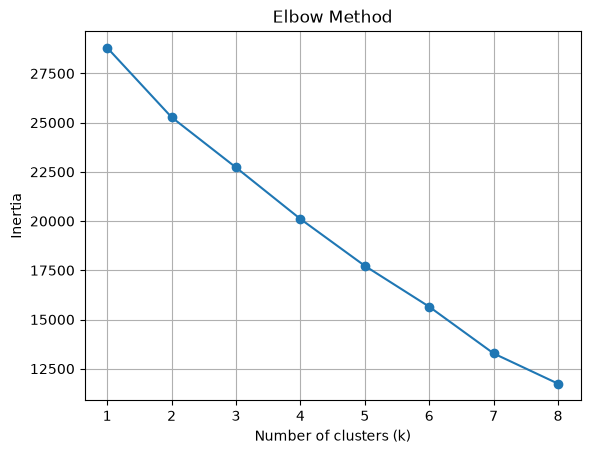

In [26]:
# (Elbow - tìm số cụm phù hợp):

# Lưu inertia của từng giá trị k
inertias = []

# Thử số cụm từ 1 đến 8
for k in range(1, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    # Huấn luyện trên dữ liệu đã chuẩn hóa
    kmeans.fit(df_scaled)

    # Lưu inertia
    inertias.append(kmeans.inertia_)

# In kết quả inertia
for k, inertia in enumerate(inertias, start=1):
    print(f'k = {k}, inertia = {inertia:.2f}')

# Vẽ biểu đồ Elbow
plt.plot(range(1, 9), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()



**Trả lời.**

7. Inertia nhỏ nhất trong bảng nằm ở k nào? Vì sao không chọn k đó làm số cụm?
8. Nhìn chỗ đường gãy, bạn chọn k nào cho phòng marketing? Có trùng k = 3 ở phần 4 không?


In [27]:
# Câu 7. Inertia nhỏ nhất trong bảng nằm tại (k=8). 
# Tuy nhiên, không nên tự động chọn (k=8) vì số cụm càng tăng thì inertia thường càng giảm. 
# Mục tiêu của Elbow là tìm số cụm cân bằng giữa độ chặt của cụm và độ phức tạp của mô hình.

# Câu 8. Dựa vào bảng số liệu, inertia giảm liên tục và chưa xuất hiện một điểm gãy thật sự nổi bật. 
# Có thể cân nhắc (k=3) để thống nhất với phần K-Means trước đó, nhưng cần xem biểu đồ thực tế và đặc điểm các cụm để quyết định. 
# Không thể khẳng định (k=3) là tối ưu chỉ từ bảng inertia này.

## 6. KNN

KNN không gom cụm. KNN cần nhãn. Nhãn là Response. Bảng đặc trưng là bảng đã ghép ở phần 2, bản chưa chuẩn hóa.

Chia train/test, test_size=0.2, random_state=0, stratify theo Response.

Tạo một scaler mới, cùng loại với phần 3. Fit scaler chỉ trên tập train, rồi transform tập test. Không dùng lại scaler đã fit trên toàn bộ dữ liệu ở phần 3.

Thử n_neighbors trong 1, 3, 5, 7, 11, 21. Với mỗi k in accuracy và F1 của lớp 1. Chọn một k và in classification_report của k đó.


In [28]:

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler

In [29]:
# (KNN – dự đoán Response):


# X là bảng đặc trưng chưa chuẩn hóa
X = df_model.copy()

# y là nhãn cần dự đoán
y = df['Response']

# Chia dữ liệu thành tập train và test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Tạo scaler mới
scaler_knn = StandardScaler()

# Chỉ fit scaler trên tập train
X_train_scaled = scaler_knn.fit_transform(X_train)

# Dùng scaler đã fit để chuẩn hóa tập test
X_test_scaled = scaler_knn.transform(X_test)

# Thử các giá trị k theo yêu cầu đề bài
k_values = [1, 3, 5, 7, 11, 21]

# Lưu F1 để chọn mô hình
f1_scores = {}

for k in k_values:
    # Khởi tạo mô hình KNN
    knn = KNeighborsClassifier(n_neighbors=k)

    # Huấn luyện mô hình
    knn.fit(X_train_scaled, y_train)

    # Dự đoán trên tập test
    y_pred = knn.predict(X_test_scaled)

    # Tính accuracy và F1 của lớp 1
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label=1)

    # Lưu F1 theo k
    f1_scores[k] = f1

    print(f'k = {k}')
    print(f'Accuracy: {acc:.4f}')
    print(f'F1 lớp 1: {f1:.4f}')
    print()

# Chọn k có F1 lớp 1 cao nhất
best_k = max(f1_scores, key=f1_scores.get)

print('k được chọn:', best_k)

# Huấn luyện lại mô hình với k đã chọn
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

# Dự đoán và in báo cáo đánh giá
y_pred = knn.predict(X_test_scaled)

print('\nClassification report:')
print(classification_report(y_test, y_pred, zero_division=0))



k = 1
Accuracy: 0.8153
F1 lớp 1: 0.3051

k = 3
Accuracy: 0.8378
F1 lớp 1: 0.2800

k = 5
Accuracy: 0.8491
F1 lớp 1: 0.2947

k = 7
Accuracy: 0.8604
F1 lớp 1: 0.2955

k = 11
Accuracy: 0.8671
F1 lớp 1: 0.2532

k = 21
Accuracy: 0.8604
F1 lớp 1: 0.1622

k được chọn: 1

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       377
           1       0.35      0.27      0.31        67

    accuracy                           0.82       444
   macro avg       0.61      0.59      0.60       444
weighted avg       0.80      0.82      0.80       444



**Trả lời.**

9. stratify theo Response giữ điều gì giữa train và test?
10. Fit scaler trên cả bảng rồi mới chia train/test thì sai ở đâu?
11. k bạn chọn là bao nhiêu? Accuracy cao hơn F1 lớp 1 thì đọc thêm chỉ số nào trước khi kết luận mô hình tốt?


In [30]:
# Câu 9. stratify=y giúp giữ tỷ lệ các lớp Response = 0 và Response = 1 tương đối giống nhau giữa tập train và tập test. 
# Điều này quan trọng vì dữ liệu có số lượng lớp 0 nhiều hơn lớp 1.

# Câu 10. Nếu fit scaler trên toàn bộ bảng trước khi chia train/test, thông tin thống kê của tập test đã được sử dụng khi chuẩn hóa. 
# Đây là hiện tượng rò rỉ dữ liệu (data leakage), khiến quy trình đánh giá không còn hoàn toàn độc lập. 
# Vì vậy, phải fit trên tập train rồi mới transform tập test.

# Câu 11. Chọn \(k=1\) theo tiêu chí F1 lớp 1 cao nhất. 
# Accuracy cao hơn F1 lớp 1 chưa đủ để kết luận mô hình tốt, đặc biệt khi hai lớp mất cân bằng. 
# Cần xem thêm precision, recall và F1-score của lớp 1, đồng thời xem confusion matrix để biết mô hình bỏ sót bao nhiêu trường hợp Response = 1.